## OLCI Sargassum Detection
`k-means clustering of daily SGI within a subset`

### 1. Import Libraries

In [1]:
import os
import glob

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.cluster import KMeans

### 2. Paths and parameters

In [2]:
zarr_root = '/home/nandii/olci_sg/day_zarrs'

# subset to view and pin in (set these to your scene)
lon_min, lon_max = -62, -58
lat_min, lat_max =  12,  16

zarr_paths = sorted(glob.glob(os.path.join(zarr_root, 'SGI_*.zarr')))
zarr_index = -1
print(f"{len(zarr_paths)} daily zarr(s) found")

# number of k-means clusters on the SGI
n_clusters = 3

276 daily zarr(s) found


### 3. Load the next day with valid pixels in the subset

Rerun this cell, then sections 4 and 5, to move to the next day.

In [14]:
# step forward to the next daily zarr with at least one pixel at or above the SGI threshold in the subset
threshold = -2

zarr_index += 1
while zarr_index < len(zarr_paths):
    ds_day = xr.open_zarr(zarr_paths[zarr_index])
    ds_sub = ds_day.sel(lon = slice(lon_min, lon_max), lat = slice(lat_min, lat_max)).load()
    n_valid  = int(np.isfinite(ds_sub['SGI_mean']).sum())
    n_sgssm  = int((ds_sub['SGI_mean'] >= threshold).sum())
    if n_sgssm > 500:
        break
    zarr_index += 1
else:
    raise StopIteration("No more daily zarrs with SGI >= threshold in the subset")

lon_sub  = ds_sub['lon'].values
lat_sub  = ds_sub['lat'].values
print(f"{ds_day.attrs['date']} (zarr {zarr_index + 1} of {len(zarr_paths)}): "
      f"subset {lat_sub.size} x {lon_sub.size} pixels, {n_valid} valid, {n_sgssm} with SGI >= {threshold}")

2018-05-24 (zarr 266 of 276): subset 1484 x 1484 pixels, 2068544 valid, 533 with SGI >= -2


### 4. Cluster the SGI with `KMeans`

In [15]:
# k-means on SGI values at or above the threshold only, one feature per pixel
sgi_2d = ds_sub['SGI_mean'].values
valid  = np.isfinite(sgi_2d) & (sgi_2d >= threshold)
sgi_1d = sgi_2d[valid].reshape(-1, 1)

kmeans = KMeans(n_clusters = n_clusters, n_init = 10, random_state = 0).fit(sgi_1d)

# relabel clusters so 0 has the lowest SGI centre and n_clusters - 1 the highest
order   = np.argsort(kmeans.cluster_centers_.ravel())
rank    = np.empty_like(order)
rank[order] = np.arange(n_clusters)
centres = kmeans.cluster_centers_.ravel()[order]

cluster_2d = np.full(sgi_2d.shape, np.nan)
cluster_2d[valid] = rank[kmeans.labels_]

# in 1-D, each boundary is the midpoint between neighbouring centres
boundaries = (centres[:-1] + centres[1:]) / 2

for k in range(n_clusters):
    print(f"cluster {k}: centre {centres[k]:.3f}, {int((cluster_2d == k).sum())} pixels")
print(f"boundaries: {np.round(boundaries, 3)}")

cluster 0: centre 2.751, 461 pixels
cluster 1: centre 24.131, 67 pixels
cluster 2: centre 90.827, 5 pixels
boundaries: [13.441 57.479]


### 5. Plot the clusters and the SGI distribution

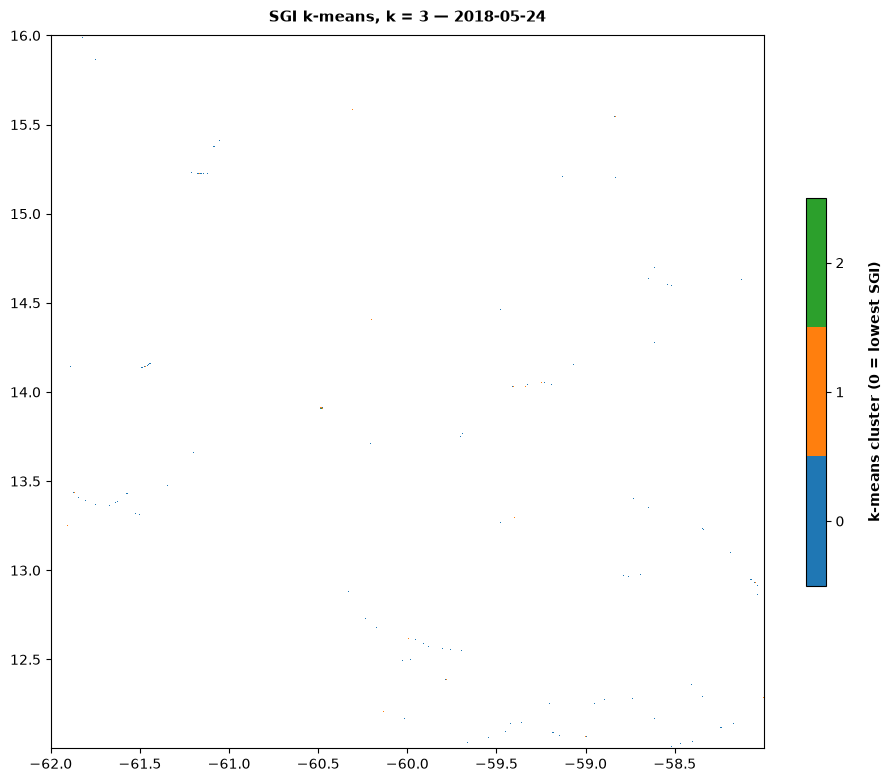

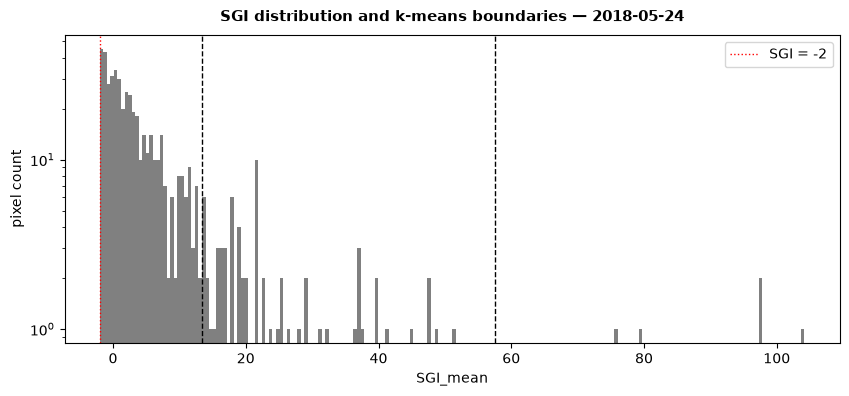

In [16]:
res    = lon_sub[1] - lon_sub[0]
extent = [lon_sub[0] - res / 2, lon_sub[-1] + res / 2, lat_sub[0] - res / 2, lat_sub[-1] + res / 2]
cmap_k = ListedColormap([plt.cm.tab10(k) for k in range(n_clusters)])

# --- Cluster map ---
fig = plt.figure(figsize = (10, 10))
ax  = plt.axes()
im  = ax.imshow(cluster_2d, origin = 'lower', extent = extent, cmap = cmap_k, interpolation = 'nearest')
im.set_clim(-0.5, n_clusters - 0.5)
cbar = plt.colorbar(im, orientation = "vertical", fraction = 0.025, pad = 0.055, ticks = range(n_clusters))
cbar.set_label(f"\nk-means cluster (0 = lowest SGI)", fontsize = 10, weight = 'bold')
ax.set_title(f"SGI k-means, k = {n_clusters} \u2014 {ds_day.attrs['date']}", fontsize = 11, weight = 'bold', pad = 10)
plt.show()

# --- SGI histogram with cluster boundaries and the -2 threshold ---
fig, ax = plt.subplots(figsize = (10, 4))
ax.hist(sgi_1d.ravel(), bins = 200, color = 'grey')
for b in boundaries:
    ax.axvline(b, color = 'black', linestyle = '--', linewidth = 1)
ax.axvline(-2, color = 'red', linestyle = ':', linewidth = 1, label = 'SGI = -2')
ax.set_yscale('log')
ax.set_xlabel('SGI_mean')
ax.set_ylabel('pixel count')
ax.legend()
ax.set_title(f"SGI distribution and k-means boundaries \u2014 {ds_day.attrs['date']}", fontsize = 11, weight = 'bold', pad = 10)
plt.show()